# Stellar winds

In [1]:
%pylab inline

Populating the interactive namespace from numpy and matplotlib


## Gato et al (2017)

From [Gatoo et al 2017](https://ui.adsabs.harvard.edu.ep.fjernadgang.kb.dk/abs/2017MNRAS.466.1903G/abstract) Paolo took (by eye) the values 

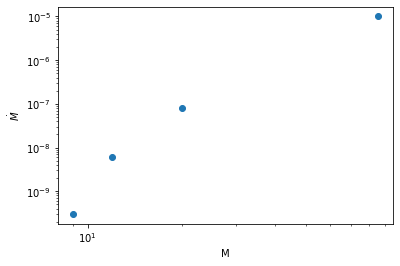

In [2]:
def plot_pp():
    m_pp=[9,12,20,85]
    mdot_pp=[3e-10,6e-9,8e-8,1e-5]
    loglog(m_pp,mdot_pp,'o')
    xlabel('M')
    ylabel('$\dot{M}$')
plot_pp()

## Dale et al (2013)

[Dale et al (2013)](https://ui-adsabs-harvard-edu.ep.fjernadgang.kb.dk/abs/2013MNRAS.436.3430D/abstract)
give an equation
$$\dot{M} = 0.3 \left( e^{M/28} - 1 \right) 10^{-6}$$
that doesn't fit the shape well:

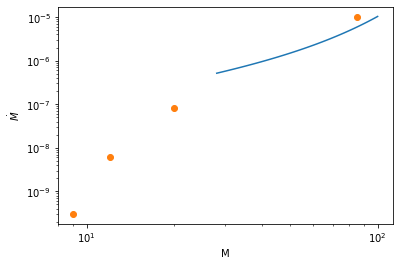

In [3]:
def mdot_dale(m):
    return (exp(m/28)-1)*3e-7
m=linspace(28,100)
loglog(m,mdot_dale(m))
plot_pp();

## Fits to the data points

Fit for mass loss rate based on log10(M/M0)**c

[-5.52098367  5.32356909  6.18458654]
[0.93013458 1.2477458  0.81514793 1.05704058]
[3.e-10 6.e-09 8.e-08 1.e-05]


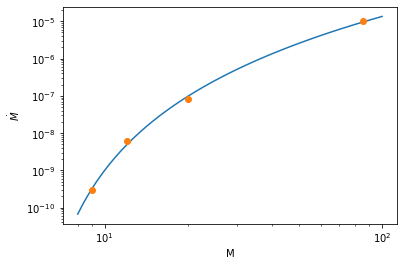

In [4]:
from scipy.optimize import curve_fit
x=[9,12,20,85]
y=[3e-10,6e-9,8e-8,1e-5]
y=log(array(y))
def test(x,a,b,c):
    return log(10.0**a*log10(x/b)**c)
bounds=([-19.,0.,3.],[-4,8.,20])
par,cov=curve_fit(test,x,y,p0=[-5,7.5,3],bounds=bounds)
print(par)
print(exp(y-test(x,par[0],par[1],par[2])))
print(exp(y))
def fit(x):
    return exp(test(x,par[0],par[1],par[2]))
x=logspace(log10(8),2)
plot(x,fit(x))
plot_pp()

A power law in (M-M0) fits within 5%

1.19e-10*(x-7.57)**2.60
[0.99111261 1.04586757 0.95060146 1.01484992]
[3.e-10 6.e-09 8.e-08 1.e-05]


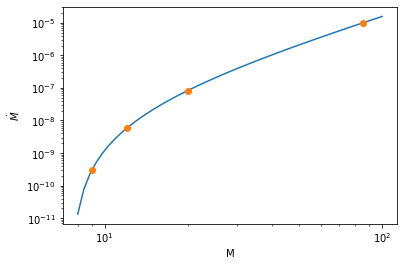

In [5]:
from scipy.optimize import curve_fit
x=[9,12,20,85]
y=[3e-10,6e-9,8e-8,1e-5]
y=log(array(y))
def test(x,a,b,c):
    return log(10.0**a*(x-b)**c)
bounds=([-13.,4.,1.],[-5,8.,4.5])
par,cov=curve_fit(test,x,y,p0=[-5,7.5,3],bounds=bounds)
print('{:.2e}*(x-{:.2f})**{:.2f}'.format(10.**par[0],par[1],par[2]))
print(exp(y-test(x,par[0],par[1],par[2])))
print(exp(y))
def fit(x):
    return exp(test(x,par[0],par[1],par[2]))
x=logspace(log10(8),2)
plot(x,fit(x))
plot_pp()

So, a good fit to Paolo's "by eye" values from [Gatoo et al 2017](https://ui.adsabs.harvard.edu.ep.fjernadgang.kb.dk/abs/2017MNRAS.466.1903G/abstract)

$$ \dot{M} = 1.2 \times 10^{-10} \,(M - 7.57)^{2.6} $$

Other "by eye" values may be accomodated by entering the values and rerun the Python fits